# Imports

In [86]:
import os

os.environ["KERAS_BACKEND"] = "torch"
import keras
import torch

In [173]:
import os
import shutil
from pathlib import Path

import h5py
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn.model_selection
import tqdm.notebook as tqdm
import transformers
from PIL import Image as PILImage
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from torchvision import datasets


In [88]:
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.is_available())

keras.mixed_precision.set_global_policy("mixed_float16")

CUDA: 12.8
GPU: True


# Data

Load and prepare your dataset. Dataset should have at least 10k samples in it. Each dataset cannot be used by more than two students.

In [89]:
def merge_folders(source: Path, destination: Path):
    source = Path(source)
    destination = Path(destination)

    for src_file in source.rglob("*"):
        relative_path = src_file.relative_to(source)
        dst_path = destination / relative_path

        if src_file.is_dir():
            dst_path.mkdir(parents=True, exist_ok=True)
            continue

        dst_path.parent.mkdir(parents=True, exist_ok=True)

        name = dst_path.stem
        ext = dst_path.suffix

        while dst_path.exists():
            name += "_"
            dst_path = dst_path.with_name(name + ext)

        shutil.copy2(src_file, dst_path)

In [90]:
DATA_DIR = Path("../../data/food11")

if not DATA_DIR.exists():
    kagglehub.dataset_download(
        "trolukovich/food11-image-dataset", output_dir=str(DATA_DIR)
    )
    merge_folders(DATA_DIR / "evaluation", DATA_DIR / "training")

print("Dataset directory:", DATA_DIR.resolve())

Dataset directory: C:\Users\Yanovich\Documents\Projects\Cats\neural\data\food11


In [91]:
for dir in DATA_DIR.iterdir():
    if dir.name.startswith("."):
        continue

    if dir.is_dir():
        print(f"{dir.name}: {len(list(dir.rglob('*.jpg')))} images")

evaluation: 3347 images
training: 13213 images
validation: 3430 images


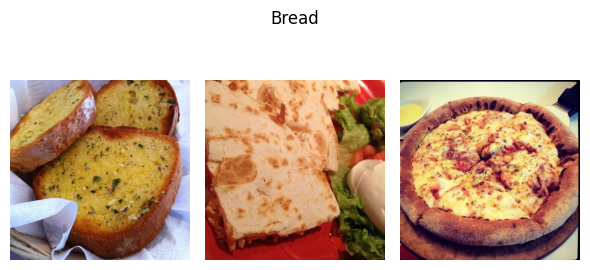

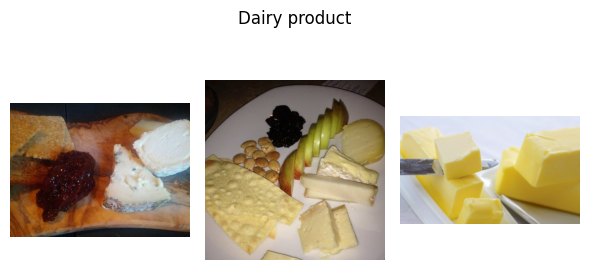

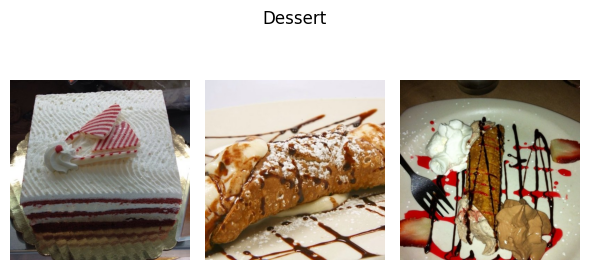

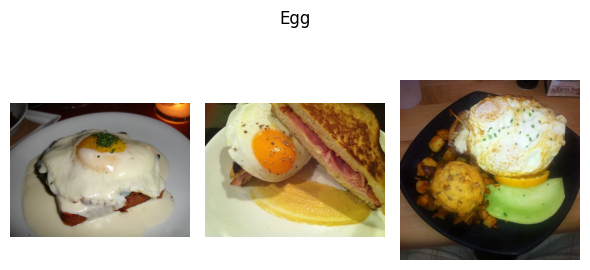

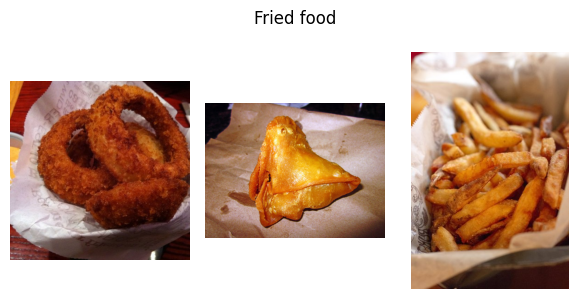

...

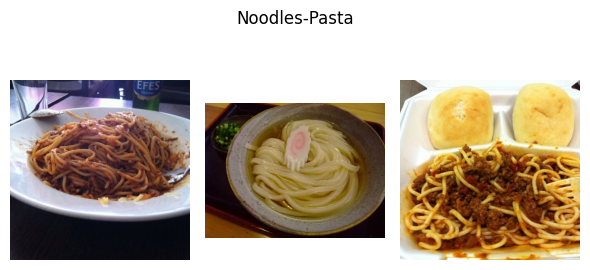

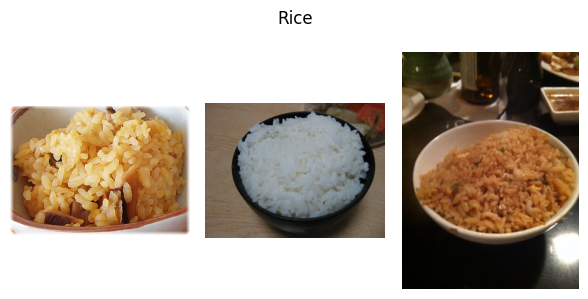

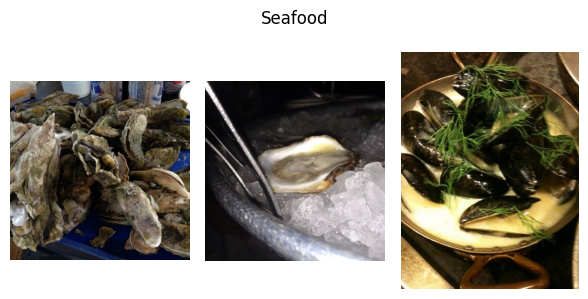

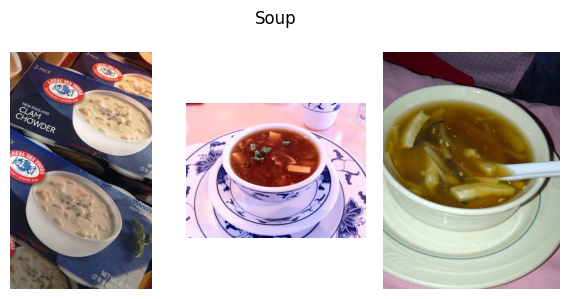

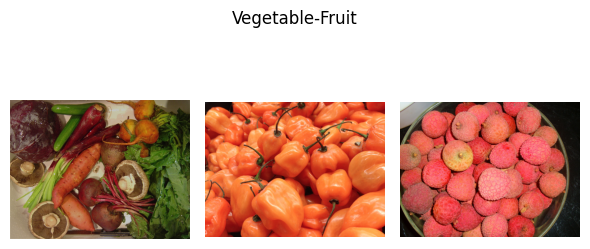

In [92]:
def sample_images_per_class(dir, samples_per_class=3):
    for cls_name in dir.iterdir():
        if cls_name.is_dir():
            images = list(cls_name.glob("*.jpg"))
            sampled_images = [images[i] for i in range(samples_per_class)]
            yield cls_name.name, [plt.imread(str(img)) for img in sampled_images]


for label, images in sample_images_per_class(DATA_DIR / "training"):
    fig, axes = plt.subplots(1, len(images), figsize=(6, 3))
    for ax, image in zip(axes, images):
        ax.imshow(image)
        ax.axis("off")
    fig.suptitle(label)
    fig.tight_layout()
    plt.show()

In [93]:
train_dataset = datasets.ImageFolder(DATA_DIR / "training")
val_dataset = datasets.ImageFolder(DATA_DIR / "validation")

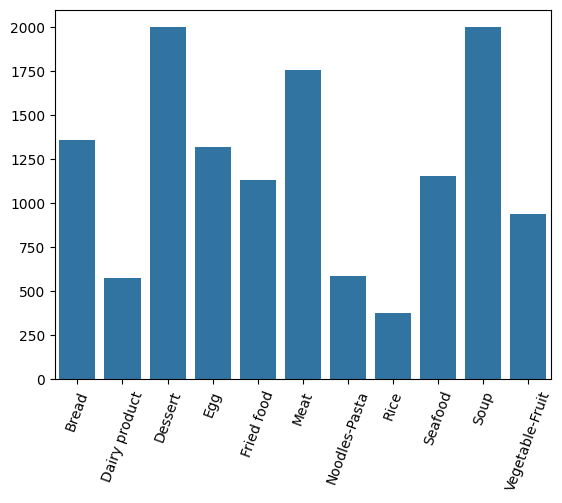

In [131]:
counts = np.bincount(train_dataset.targets)

sns.barplot(x=train_dataset.classes, y=counts)
_ = plt.xticks(rotation=70)

# Backbone

Load pretrained model from Hugging Face (or some other model repository if it's more convenient). Model should be trained on Feature Extraction task.

In [94]:
BACKBONE_NAME = "google/siglip2-base-patch16-256"

In [95]:
backbone = transformers.AutoModel.from_pretrained(BACKBONE_NAME)

In [96]:
backbone.to("cuda" if torch.cuda.is_available() else "cpu")
backbone.eval()

SiglipModel(
  (text_model): SiglipTextTransformer(
    (embeddings): SiglipTextEmbeddings(
      (token_embedding): Embedding(256000, 768)
      (position_embedding): Embedding(64, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): SiglipMLP(
            (activation_fn): GELUTanh()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_feature

In [97]:
total_params = sum(p.numel() for p in backbone.parameters())
print(f"Total params: {total_params/1e6:.2f}M")

Total params: 375.23M


Load tokenizer to be used with the model

In [98]:
processor = transformers.AutoImageProcessor.from_pretrained(BACKBONE_NAME)

In [99]:
processor.size

{'height': 256, 'width': 256}

# Feature extraction

Since we will not be training the backbone, extract features from your dataset.

Run the backbone on the images and save the extracted features. Don't forget to process the images. Images don't have to be of the same size, though it would be faster if they were. If the images don't fit in memory, lazily load them from disk

In [100]:
def extract_embeddings(
    dataset,
    output_path,
    backbone,
    image_processor,
    batch_size=128,
):
    if output_path.exists():
        print(f"Output file {output_path} already exists. Skipping extraction.")
        return

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    backbone.to(device).eval()

    num_images = len(dataset)
    embedding_dim = backbone.config.vision_config.hidden_size

    with h5py.File(output_path, "w") as h5_file:
        features_ds = h5_file.create_dataset(
            "embeddings",
            shape=(num_images, embedding_dim),
            dtype="float32",
            chunks=(min(batch_size, num_images), embedding_dim),
            compression="gzip",
        )
        labels_ds = h5_file.create_dataset("labels", shape=(num_images,), dtype="int64")
        paths_ds = h5_file.create_dataset(
            "paths", shape=(num_images,), dtype=h5py.string_dtype(encoding="utf-8")
        )
        h5_file.attrs["classes"] = np.asarray(
            dataset.classes, dtype=h5py.string_dtype(encoding="utf-8")
        )

        with torch.inference_mode():
            for start in tqdm.tqdm(range(0, num_images, batch_size)):
                end = min(start + batch_size, num_images)
                paths = [dataset.samples[i][0] for i in range(start, end)]
                labels = [dataset.samples[i][1] for i in range(start, end)]
                images = [dataset[i][0] for i in range(start, end)]

                inputs = image_processor(images=images, return_tensors="pt")
                pixel_values = inputs["pixel_values"].to(device)
                batch_embeddings = backbone.vision_model(
                    pixel_values=pixel_values
                ).pooler_output

                features_ds[start:end] = batch_embeddings.cpu().numpy()
                labels_ds[start:end] = labels
                paths_ds[start:end] = paths

    print(f"Saved {num_images} embeddings to {output_path}")

In [101]:
extract_embeddings(
    train_dataset,
    DATA_DIR / "train_embeddings.h5",
    backbone,
    processor
)

Output file ..\..\data\food11\train_embeddings.h5 already exists. Skipping extraction.


In [102]:
extract_embeddings(
    val_dataset,
    DATA_DIR / "val_embeddings.h5",
    backbone,
    processor
)

Output file ..\..\data\food11\val_embeddings.h5 already exists. Skipping extraction.


# Prepare train/test data

Split your data (extracted features and labels) into train and test subsets.

In [103]:
class H5EmbeddingDataset(keras.utils.PyDataset):
    def __init__(
        self,
        h5_path,
        shuffle=False,
        batch_size=128,
        rng=None,
        **kwargs,
    ):
        super().__init__(**kwargs)

        if rng is None:
            rng = np.random.default_rng() if rng is None else rng

        self.h5_path = str(h5_path)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = rng

        with h5py.File(self.h5_path, "r") as h5_file:
            num_samples = h5_file["embeddings"].shape[0]
            embeddings = h5_file["embeddings"][:]
            labels = h5_file["labels"][:]

        self.embeddings = embeddings.astype(np.float32, copy=False)
        self.labels = labels.astype(np.int64, copy=False)

        self.indices = np.arange(num_samples)
        self.on_epoch_begin()

    def __len__(self):
        return -(-len(self.indices) // self.batch_size)

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        batch_indices = self.indices[start : start + self.batch_size]

        features = self.embeddings[batch_indices]
        labels = self.labels[batch_indices]

        return features, labels

    def on_epoch_begin(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

Prepare `tf.data.Dataset` or some other way for the data to be used during training.

In [104]:
train_ds = H5EmbeddingDataset(DATA_DIR / "train_embeddings.h5", shuffle=True)

In [105]:
val_ds = H5EmbeddingDataset(DATA_DIR / "val_embeddings.h5", shuffle=False)

In [106]:
train_ds[0]

(array([[ 0.19645816,  0.46575218, -0.02277213, ...,  0.13316359,
         -0.27206916,  0.06880651],
        [ 0.17524093,  0.50712687, -0.3661256 , ..., -0.11791599,
         -0.18205577,  0.41574082],
        [ 0.15331802, -0.59290427, -0.3042672 , ..., -0.39392418,
          0.08719742,  0.20316637],
        ...,
        [ 0.16635074,  0.16886508,  0.17841542, ...,  0.03203487,
         -0.13407837,  0.48803824],
        [ 0.07258499, -0.20523208, -0.18661384, ...,  0.16874114,
         -0.36717018,  0.04586506],
        [-0.43780422, -0.28159073, -0.27026457, ..., -0.10904886,
          0.02639905, -0.13704057]], shape=(128, 768), dtype=float32),
 array([ 6,  6,  2,  4,  8, 10,  8, 10,  4,  5,  5,  2,  3, 10,  3,  0,  5,
         8, 10,  4,  4,  4,  3,  4, 10,  5,  6,  4,  3, 10,  0,  5,  9,  1,
         8,  8,  0,  7,  0,  8,  3,  3,  9,  5,  9,  4,  9,  3,  2,  2,  8,
         3,  2,  3,  2,  2,  9,  2,  5,  2,  2,  1,  0,  3,  5,  3,  2,  0,
         5,  0,  4,  5,  3,  3,  0, 

# Build the model

Build a simple model. The model should accept an extracted feature vector and return a vector of class logits (or probabilities). Model should only have a couple (or even 1) layers with weights.

In [107]:
inputs = x = keras.layers.Input(
    shape=(backbone.config.vision_config.hidden_size,), name="embedding"
)
x = keras.layers.Dense(len(train_dataset.classes), name="logits")(x)

model = keras.Model(inputs=inputs, outputs=x, name="feature_extraction_head")
model.summary()

Model: "feature_extraction_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (InputLayer)          │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 11)             │         8,459 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,459 (33.04 KB)

 Trainable params: 8,459 (33.04 KB)

 Non-trainable params: 0 (0.00 B)

Compile the model. Choose loss and metrics.

In [108]:
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

# Train the model

In [109]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=2,
            restore_best_weights=True,
        )
    ],
)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8326 - loss: 0.8510 - val_accuracy: 0.9781 - val_loss: 0.2501
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9844 - loss: 0.1637 - val_accuracy: 0.9843 - val_loss: 0.1243
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9886 - loss: 0.0953 - val_accuracy: 0.9848 - val_loss: 0.0874
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9904 - loss: 0.0696 - val_accuracy: 0.9857 - val_loss: 0.0706
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9915 - loss: 0.0561 - val_accuracy: 0.9857 - val_loss: 0.0607
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9924 - loss: 0.0475 - val_accuracy: 0.9860 - val_loss: 0.0543
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9930 - loss: 0.0414 - val_accuracy: 0.9878 - val_loss: 0.0495
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9936 - loss: 0.0368 - val_accu

# Evaluation

Evalute the model on test data.

In [133]:
predictions = np.argmax(model.predict(val_ds), axis=1)
accuracy = accuracy_score(val_ds.labels, predictions)
print(f"Validation accuracy: {accuracy:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Validation accuracy: 0.9880


Plot confusion matrix.

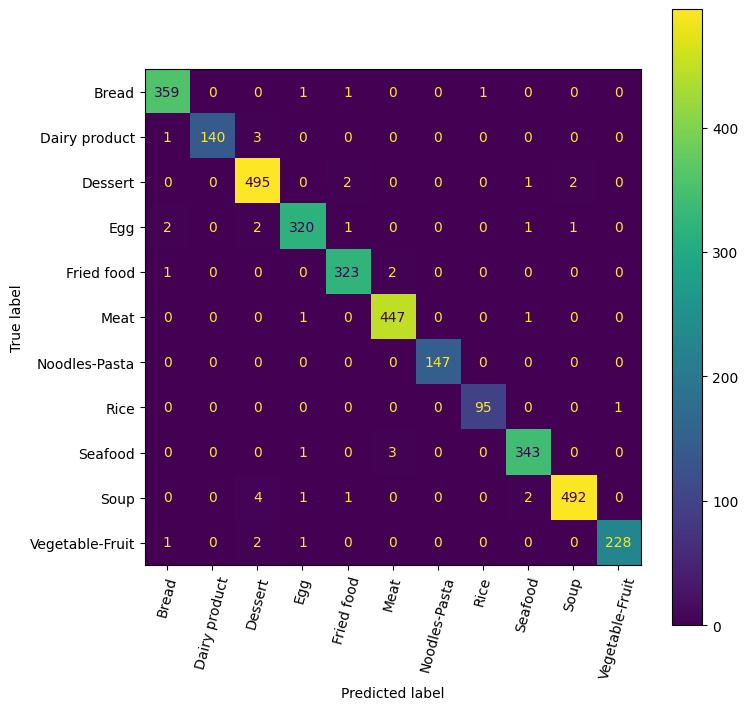

In [134]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(val_ds.labels, predictions, ax=ax, display_labels=train_dataset.classes)
_ = plt.xticks(rotation=75)

Perform dimensiality reduction and plot the extracted features. Do classes form clusters?

In [ ]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42,
)
embedding_2d = tsne.fit_transform(val_ds.embeddings)

In [207]:
def plot_tsne(class_names: list, figsize: tuple[int, int] = (8, 6)):
    _, ax = plt.subplots(figsize=figsize)
    for class_id, class_name in enumerate(train_dataset.classes):
        if class_name not in class_names:
            continue
        mask = val_ds.labels == class_id
        markers = ["v", "o", "s", "D", "^", "<", ">", "p", "*", "h", "H"]
        ax.scatter(
            embedding_2d[mask, 0],
            embedding_2d[mask, 1],
            label=f"{class_id}: {class_name}",
            s=24,
            alpha=0.7,
            marker=markers[class_id % len(markers)],
        )

    ax.set(title="t-SNE of validation embeddings", xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.show()

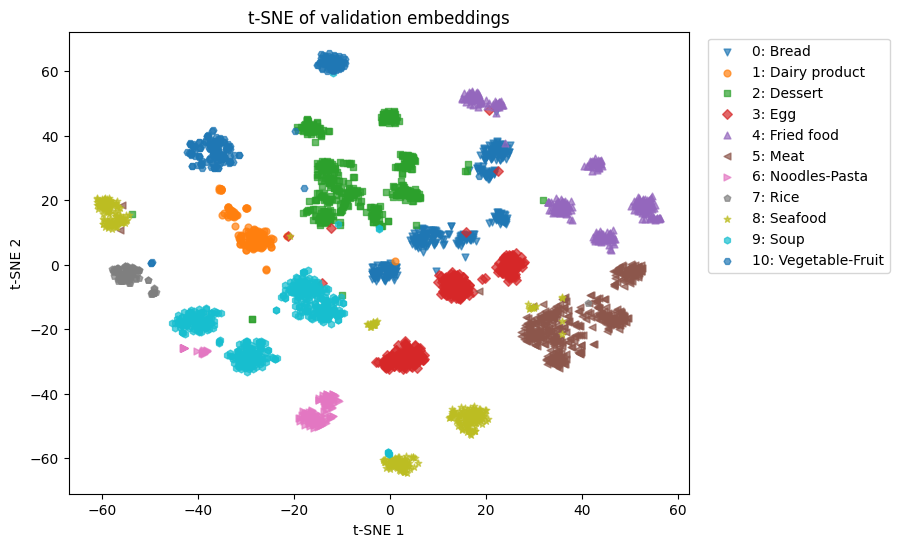

In [209]:
plot_tsne(class_names=train_dataset.classes)

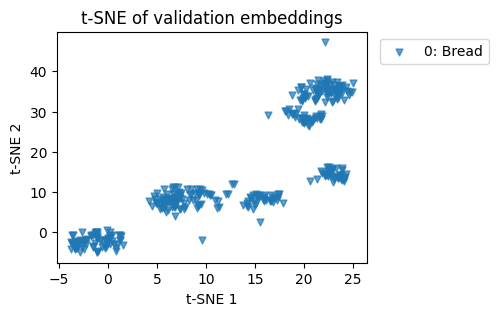

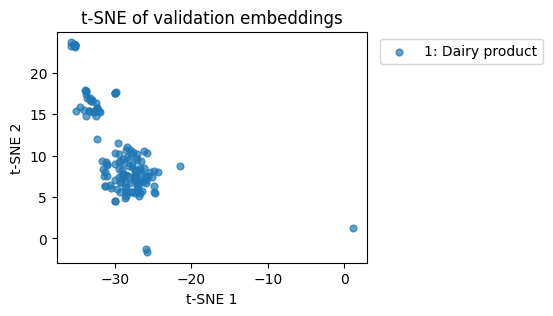

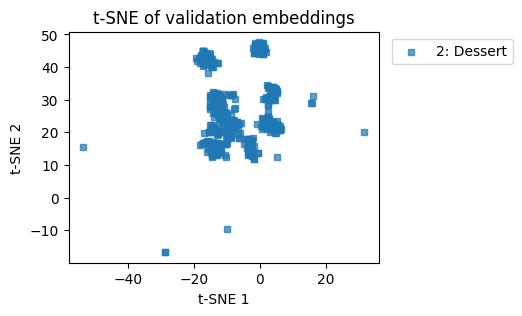

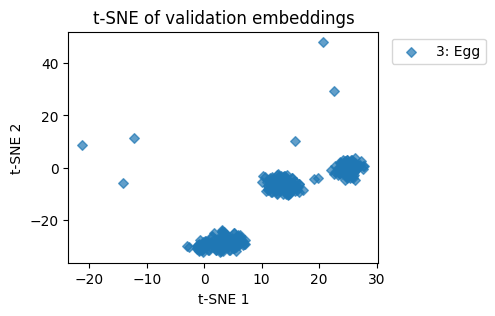

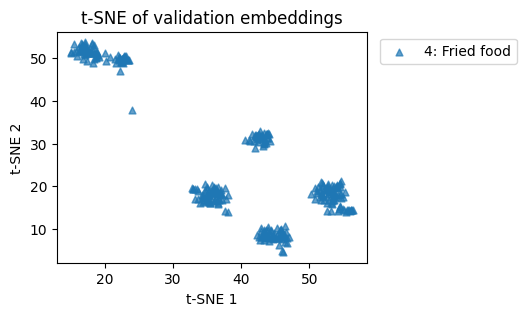

...

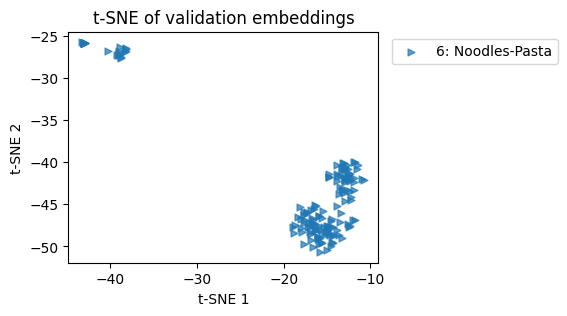

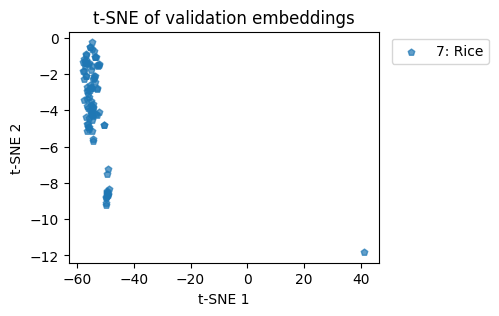

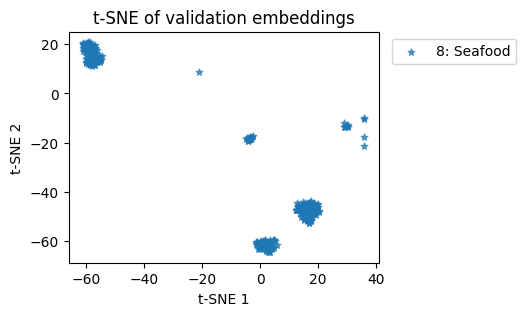

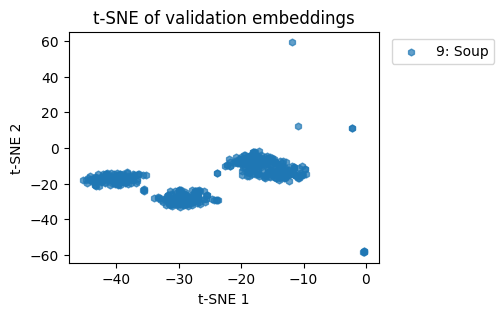

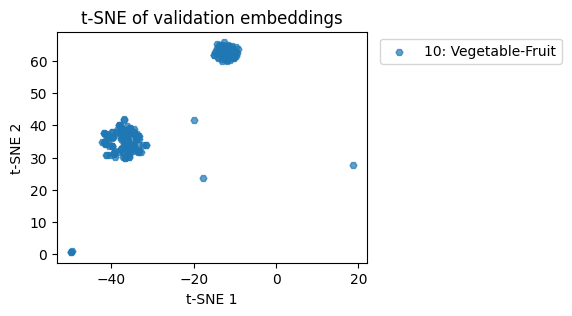

In [210]:
for class_id, class_name in enumerate(train_dataset.classes):
    plot_tsne(class_names=[class_name], figsize=(4, 3))

In [ ]:
def cluster_class_dbscan(
    class_id,
    eps=0.5,
    min_samples=5,
    n_examples_per_cluster=3,
):
    class_indices = np.flatnonzero(val_ds.labels == class_id)
    if len(class_indices) == 0:
        print(f"No validation samples for class {class_id}.")
        return

    features = val_ds.embeddings[class_indices]
    features = features / np.maximum(
        np.linalg.norm(features, axis=1, keepdims=True), 1e-12
    )

    labels = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean").fit_predict(
        features
    )

    cluster_ids = sorted(set(labels) - {-1})
    if -1 in labels:
        cluster_ids.append(-1)

    _, axes = plt.subplots(
        len(cluster_ids),
        n_examples_per_cluster,
        figsize=(2 * n_examples_per_cluster, 2 * len(cluster_ids)),
        squeeze=False,
    )

    for row, cluster_id in enumerate(cluster_ids):
        members = np.flatnonzero(labels == cluster_id)

        if cluster_id == -1:
            selected = members[:n_examples_per_cluster]
            title = "Noise"
        else:
            center = features[members].mean(axis=0)
            distances = np.linalg.norm(features[members] - center, axis=1)
            selected = members[np.argsort(distances)[:n_examples_per_cluster]]
            title = f"Cluster {cluster_id}"

        for col in range(n_examples_per_cluster):
            ax = axes[row, col]
            if col < len(selected):
                dataset_idx = class_indices[selected[col]]
                image, _ = val_dataset[dataset_idx]
                ax.imshow(image)
                ax.set_title(title)
            ax.axis("off")

    class_name = val_dataset.classes[class_id]
    plt.suptitle(f"{class_name} — DBSCAN (eps={eps}, min_samples={min_samples})")
    plt.tight_layout()
    plt.show()

    print("Samples per cluster:", {
        "noise": int(np.sum(labels == -1)),
        **{int(cluster_id): int(np.sum(labels == cluster_id)) for cluster_id in cluster_ids if cluster_id != -1},
    })

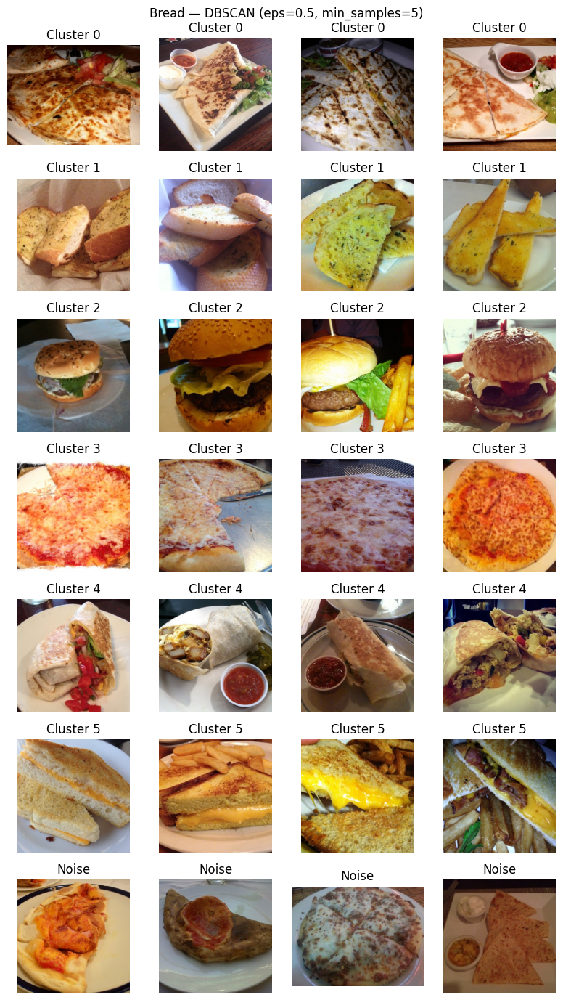

Samples per cluster: {'noise': 139, 0: 61, 1: 47, 2: 26, 3: 43, 4: 28, 5: 18}


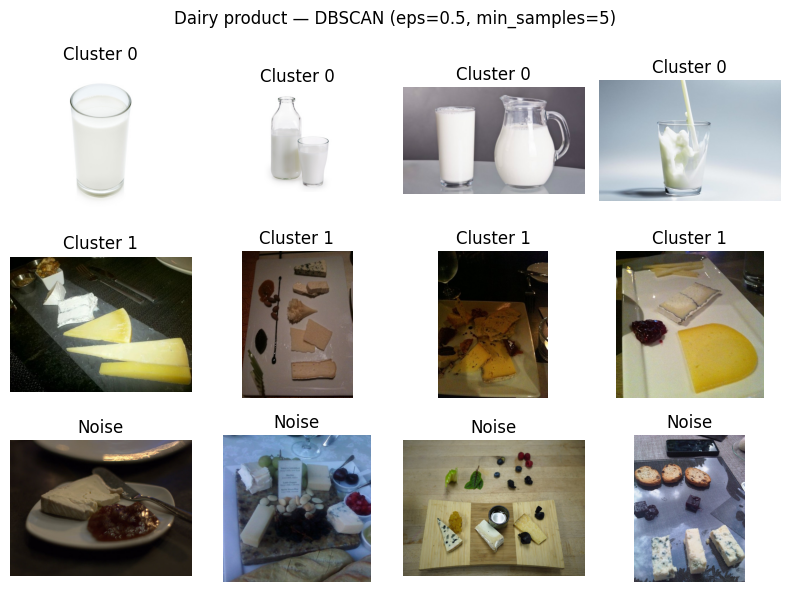

Samples per cluster: {'noise': 75, 0: 10, 1: 59}


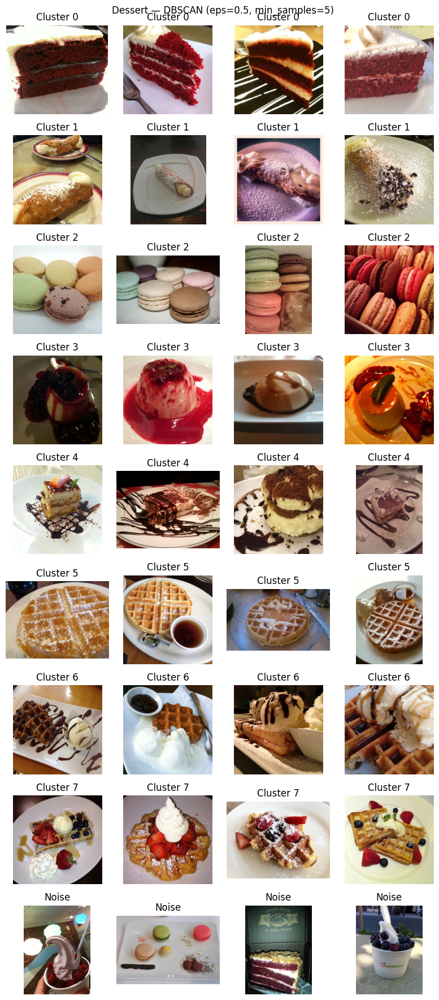

Samples per cluster: {'noise': 319, 0: 44, 1: 35, 2: 36, 3: 25, 4: 22, 5: 8, 6: 5, 7: 6}


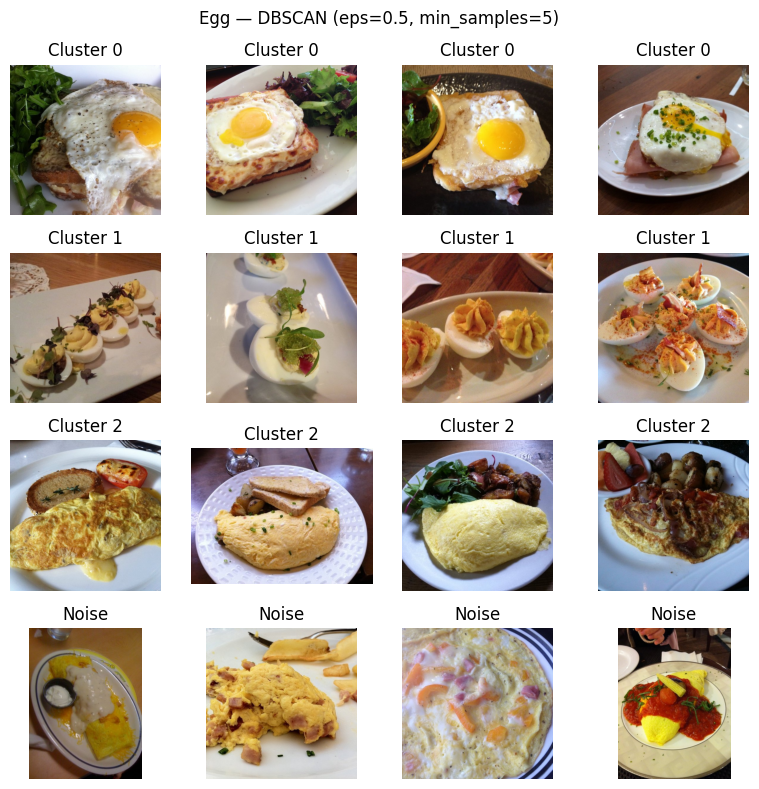

Samples per cluster: {'noise': 81, 0: 86, 1: 116, 2: 44}


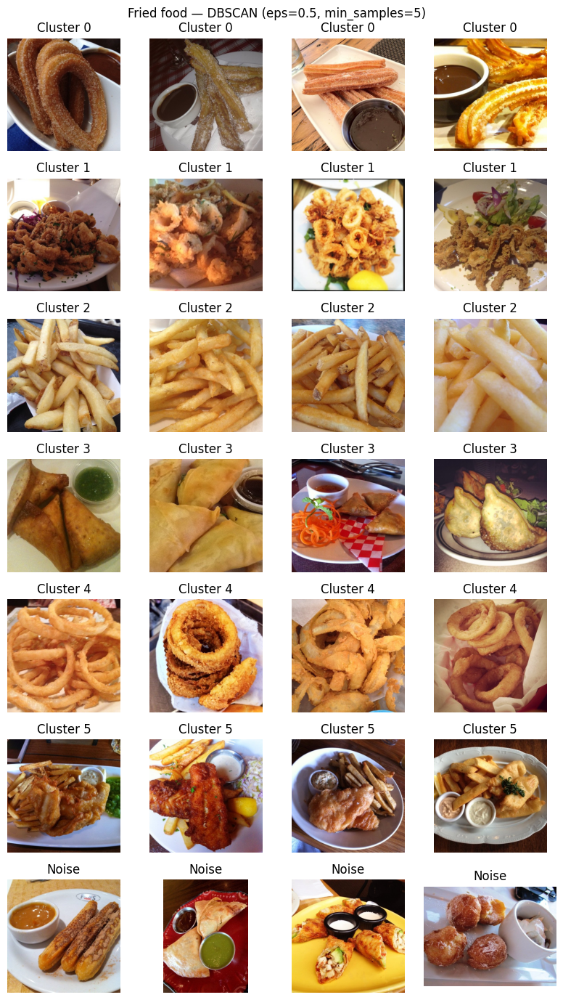

Samples per cluster: {'noise': 56, 0: 31, 1: 8, 2: 59, 3: 67, 4: 57, 5: 48}


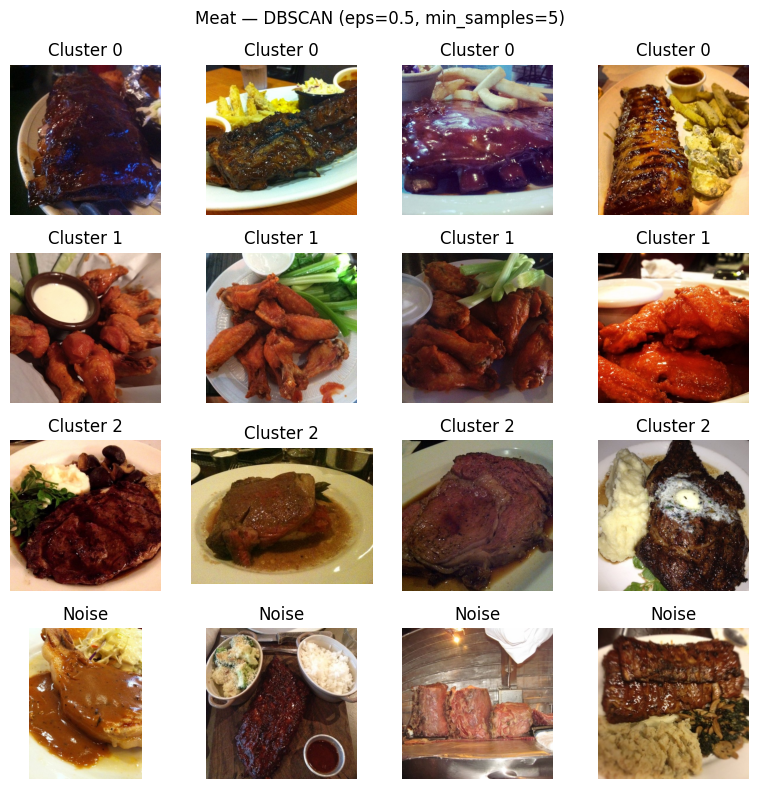

Samples per cluster: {'noise': 180, 0: 66, 1: 65, 2: 138}


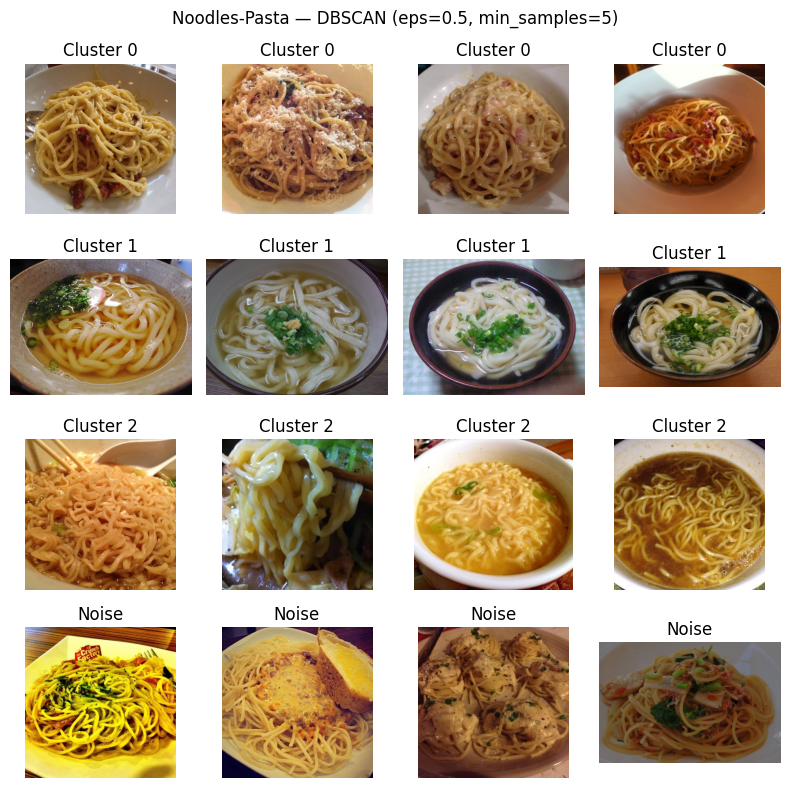

Samples per cluster: {'noise': 21, 0: 110, 1: 10, 2: 6}


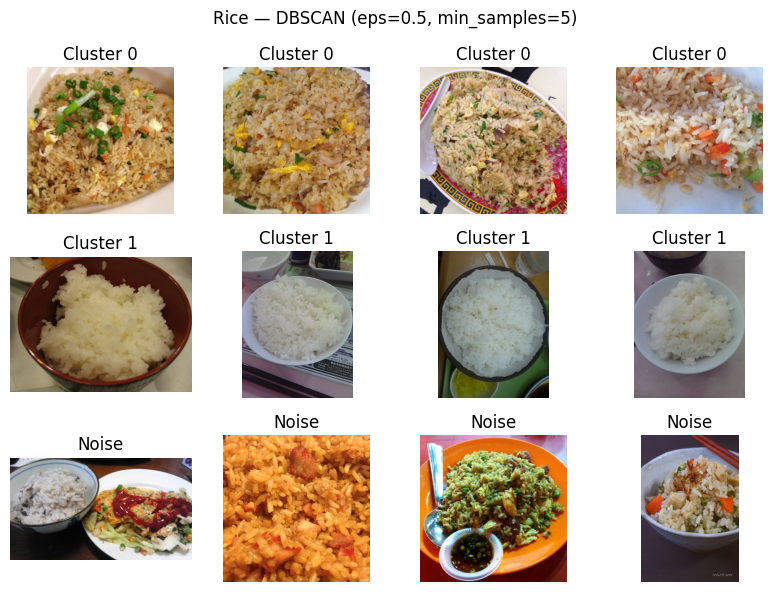

Samples per cluster: {'noise': 12, 0: 70, 1: 14}


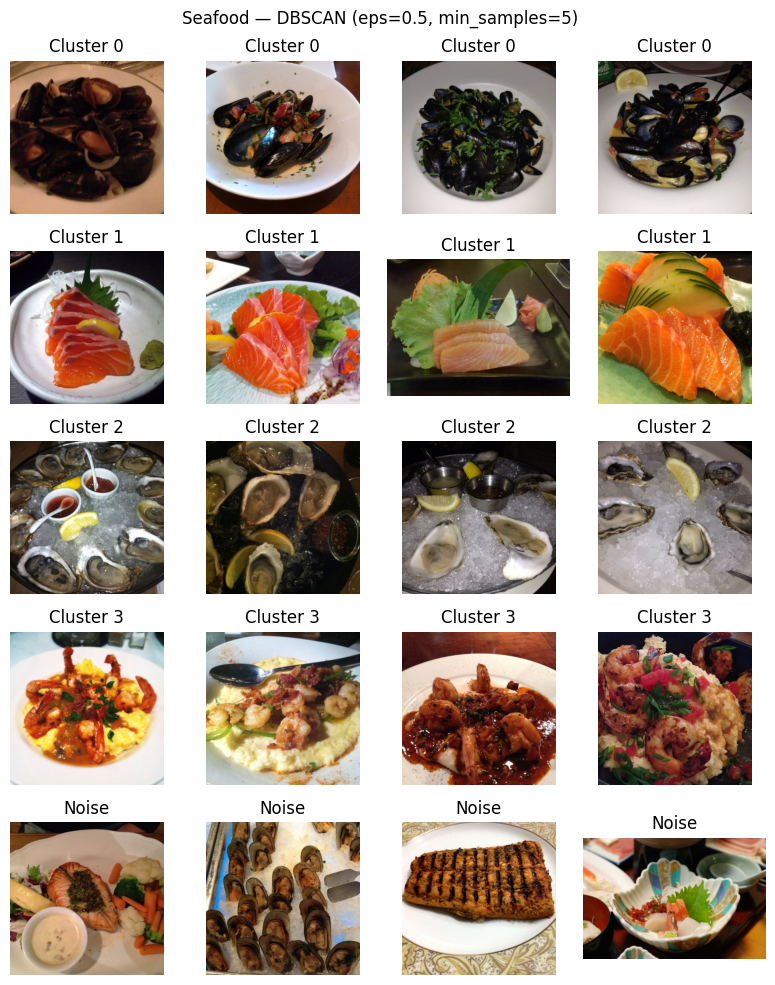

Samples per cluster: {'noise': 51, 0: 68, 1: 104, 2: 111, 3: 13}


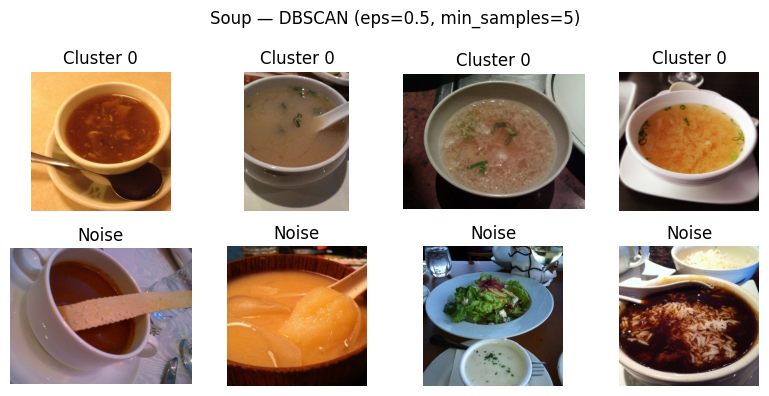

Samples per cluster: {'noise': 73, 0: 427}


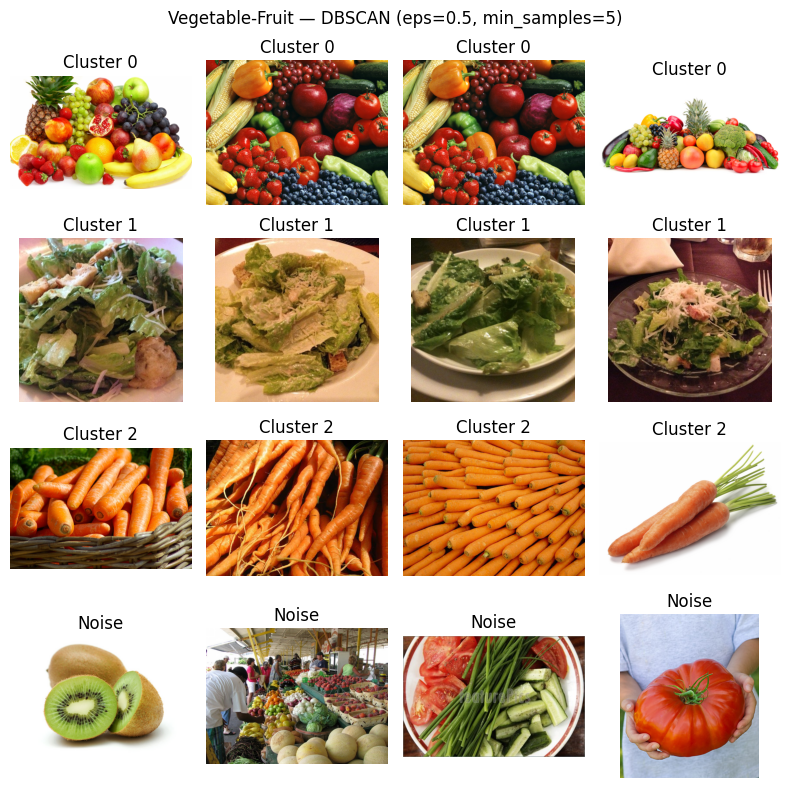

Samples per cluster: {'noise': 83, 0: 67, 1: 75, 2: 7}


In [236]:
for i in range(len(train_dataset.classes)):
    cluster_class_dbscan(class_id=i, eps=0.5, n_examples_per_cluster=4)

# Bonus

Check if the feature extractor model can be used without a classifier layer (how large is the average feature vector similarity inbetween same in different classes)

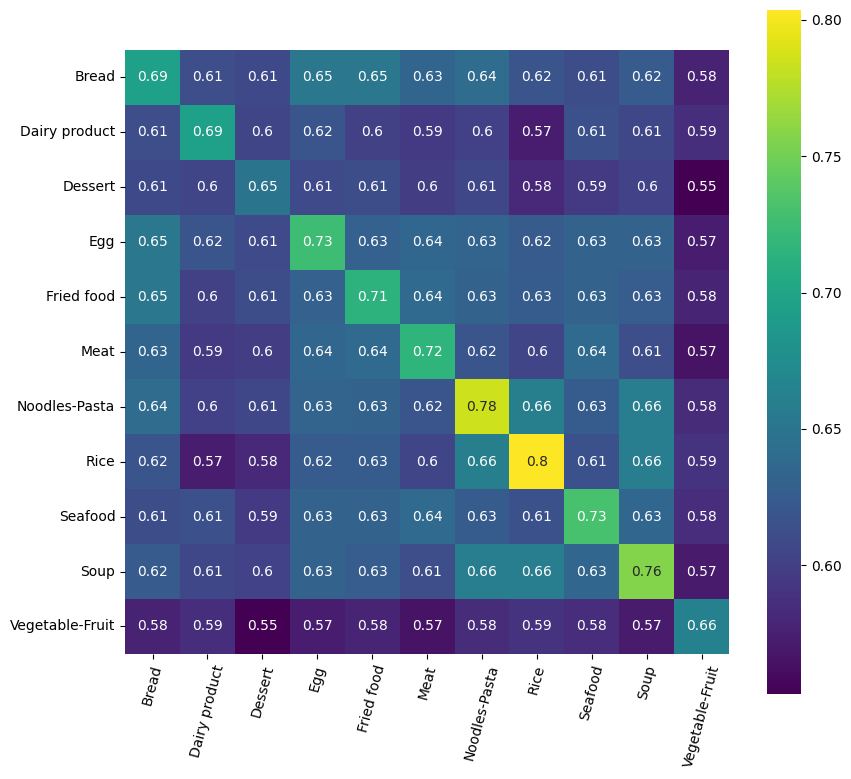

Среднее косинусное сходство внутри класса:  0.7098
Среднее косинусное сходство между классами: 0.6137
Разница (внутри - между): 0.0960


In [243]:
embeddings = val_ds.embeddings.astype(np.float32)
labels = val_ds.labels
class_names = train_dataset.classes

normalized = embeddings / np.maximum(
    np.linalg.norm(embeddings, axis=1, keepdims=True), 1e-12
)

similarity = normalized @ normalized.T

num_classes = len(class_names)
class_indices = [np.flatnonzero(labels == class_id) for class_id in range(num_classes)]

matrix = np.empty((num_classes, num_classes), dtype=np.float32)
for a in range(num_classes):
    idx_a = class_indices[a]
    for b in range(num_classes):
        idx_b = class_indices[b]
        block = similarity[np.ix_(idx_a, idx_b)]
        if a == b:
            matrix[a, b] = (block.sum() - len(idx_a)) / (len(idx_a) * (len(idx_a) - 1))
        else:
            matrix[a, b] = block.mean()

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(
    matrix,
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="viridis",
    annot=True,
    square=True,
    ax=ax,
)

plt.xticks(rotation=75)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

same_class = labels[:, None] == labels[None, :]
eye = np.eye(len(labels), dtype=bool)

within = similarity[same_class & ~eye].mean()
between = similarity[~same_class].mean()

print(f"Среднее косинусное сходство внутри класса:  {within:.4f}")
print(f"Среднее косинусное сходство между классами: {between:.4f}")
print(f"Разница (внутри - между): {within - between:.4f}")